# 12. Two Dimensions

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

In the previous chapter, we solved a one-dimensional problem—a penny falling from the Empire State Building. Now we’ll solve a two-dimensional problem—finding the trajectory of a baseball.

To do that, we’ll use spatial vectors to represent quantities in two and three dimensions, including force, acceleration, velocity, and position.

## Spatial Vectors

The word *vector* means different things to different people. In MATLAB, a vector is a matrix that has either one row or one column. So far, we’ve used MATLAB vectors to represent the following:

-   **Sequences**: A mathematical sequence, like the Fibonacci numbers, is a set of values identified by integer indices; in Section 4.5, we used a MATLAB vector to store the elements of a sequence.

-   **State vectors**: A state vector is a set of values that describes the state of a physical system. When you call `ode45`, you give it initial conditions in a state vector. Then, when `ode45` calls your rate function, it gives you a state vector.

-   **Time series**: One of the results from `ode45` is a vector that represents a sequence of time values.

In this chapter, we’ll see another use of MATLAB vectors: representing *spatial vectors*. A spatial vector represents a multidimensional physical quantity like position, velocity, acceleration, or force.

For example, to represent a position in two-dimensional space, we can use a vector with two elements:

In [ ]:
P = [3 4]

To interpret this vector, we have to know the coordinate system it is defined in. Most commonly, we use a Cartesian system where the x-axis points east and the y-axis points north. In that case `P` represents a point 3 units east and 4 units north of the origin.

When a spatial vector is represented in this way, we can use it to compute the magnitude and direction of a physical quantity. For example, the *magnitude* of `P` is the distance from the origin to `P`, which is the hypotenuse of the triangle with sides `P(1)` and `P(2)`. We can compute it using the Pythagorean theorem:

In [ ]:
sqrt(P(1)^2 + P(2)^2)

Or we can do the same thing using the function `norm`, which computes the *Euclidean norm* of a vector, which is its magnitude:

In [ ]:
norm(P)

There are two ways to get the *direction* of a vector. One convention is to compute the angle between the vector and the x-axis:

In [ ]:
atan2(P(2), P(1))

In this example, the angle is about 0.9 rad. But for computational purposes, we often represent direction with a *unit vector*, which is a vector with length 1. To get a unit vector we can divide a vector by its length:

In [ ]:
function res = hat(V)
    res = V / norm(V)
end

In [ ]:
hat(P)

This function takes a vector, `V`, and returns a unit vector with the same direction as `V`. It’s called `hat` because in mathematical notation, unit vectors are written with a “hat” symbol. For example, the unit vector with the same direction as $\mathbf{P}$ would be written $\hat{\mathbf{P}}$.

## Adding Vectors

Vectors are useful for representing quantities like force and acceleration because we can add them up without having to think explicitly about direction.

As an example, suppose we have two vectors representing forces:

In [ ]:
A = [2, 4];
B = [2, -2];

`A` represents a force pulling northeast; `B` represents a force pulling southeast, as shown in Figure 12.1:

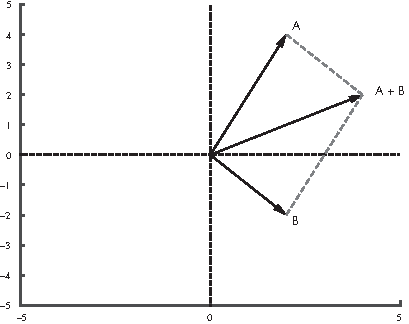

*Figure 12.1: The sum of two forces represented by vectors*

To compute the sum of these forces, all we have to do is add the vectors:

In [ ]:
A + B

Later in the chapter, we’ll use vector addition to add accelerations due to different forces acting on a baseball.

## ODEs in Two Dimensions

So far we’ve used `ode45` to solve a system of first-order equations and a single second-order equation. Now we’ll take one more step, solving a system of second-order equations.

As an example, we’ll simulate the flight of a baseball. If there is no wind and no spin on the ball, the ball travels in a vertical plane, so we can think of the system as two-dimensional, with $x$ representing the horizontal distance traveled from the starting place and $y$ representing height or altitude.

Listing 12.1 shows a rate function we can use to simulate this system with `ode45`:

*Listing 12.1: A rate function we can use to model the flight of a baseball*

In [ ]:
function res = rate_func(t, W)
    P = W(1:2);
    V = W(3:4);

    dPdt = V;
    dVdt = acceleration(t, P, V);

    res = [dPdt; dVdt];
end

function res = acceleration(t, P, V)
    g = 9.8;             % acceleration due to gravity in m/s^2
    a_gravity = [0; -g];
    res = a_gravity;
end

The second argument of `rate_func` is understood to be a vector, `W`, with four elements. The first two are assigned to `P`, which represents position; the last two are assigned to `V`, which represents velocity. Both `P` and `V` have two elements, representing the $x$ and $y$ components.

The goal of the rate function is to compute the derivative of `W`, so the output has to be a vector with four elements, where the first two represent the derivative of `P` and the last two represent the derivative of `V`. The derivative of `P` is velocity. We don’t have to compute it; we were given it as part of `W`. The derivative of `V` is acceleration. To compute it, we call `acceleration`, which takes as input variables time, position, and velocity. In this example, we don’t use any of the input variables, but we will soon.

For now we’ll ignore air resistance, so the only force on the baseball is gravity. We represent acceleration due to gravity with a vector that has magnitude `g` and direction along the negative y-axis.

Let’s assume that a ball is batted from an initial position 1 m above the home plate, with an initial velocity of 40 m/s in the horizontal and 30 m/s in the vertical direction.

Here’s how we can call `ode45` with these initial conditions:

In [ ]:
P = [0; 1];       % initial position in m
V = [40; 30];     % initial velocity in m/s
W = [P; V];       % initial condition

tspan = [0 6]
[T, M] = ode45(@rate_func, tspan, W);

`P` and `V` are column vectors because we put semicolons between the elements. So `W` is a column vector with four elements. And `tspan` specifies that we want to run the simulation for 6 s.

The output variables from `ode45` are a vector, `T`, that contains time values and a matrix, `M`, with four columns: the first two are position; the last two are velocity.

Here’s how we can plot position as a function of time:

In [ ]:
X = M(:, 1);
Y = M(:, 2);

hold on
plot(T, X)
plot(T, Y)

`X` and `Y` get the first and second columns from `M`, which are the $x$ and $y$ position coordinates.

Figure 12.2 shows what these coordinates look like as a function of time. The x-coordinate increases linearly because the $x$ velocity is constant. The y-coordinate goes up and down, as we expect.

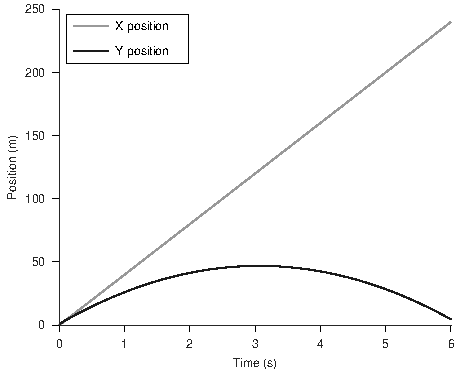

*Figure 12.2: Simulated flight of a baseball neglecting drag force*

The simulation ends just before the ball lands, having traveled almost 250 m. That’s substantially farther than a real baseball would travel, because we have ignored air resistance, or “drag force.”

## Drag Force

A simple model for the drag force on a baseball is

$$\mathbf{F}_\mathrm{d} = - \frac{1}{2} \, \rho v C_\mathrm{d} A \hat{\mathbf{V}}$$ where $\mathbf{F}_\mathrm{d}$ is a vector that represents the force on the baseball due to drag, $\rho$ is the density of air, $C_\mathrm{d}$ is the drag coefficient, and $A$ is the cross-sectional area.

$\mathbf{V}$ is the baseball’s velocity vector, $v$ is the magnitude of $\mathbf{V}$, and $\hat{\mathbf{V}}$ is a unit vector in the same direction as $\mathbf{V}$. The minus sign at the beginning means that the result is in the opposite direction to $\mathbf{V}$.

The function in Listing 12.2 computes the drag force on a baseball:

*Listing 12.2: A function that calculates the drag force on a baseball*

In [ ]:
 function res = drag_force(V)
    C_d = 0.3;      % dimensionless
    rho = 1.3;      % kg / m^3
    A = 0.0042;     % m^2
    v = norm(V);    % m/s

    res = -1/2 * C_d * rho * A * v * V;
end

The drag coefficient for a baseball is about 0.3. The density of air at sea level is about 1.3 kg/m³. The cross-sectional area of a baseball is 0.0042 m².

Now we have to update `acceleration` to take drag into account:

In [ ]:
function res = acceleration(t, P, V)
    g = 9.8;                       % acceleration due to gravity in m/s^2
    a_gravity = [0; -g];

    m = 0.145;                     % mass in kilograms
    a_drag = drag_force(V) / m;
    res = a_gravity + a_drag;
end

In [ ]:
% Run the simulation again with drag (Figure 12.4)
[T, M] = ode45(@rate_func, tspan, W);
X = M(:, 1);
Y = M(:, 2);

hold on
plot(T, X)
plot(T, Y)

As in Listing 12.1, `acceleration` represents acceleration due to gravity with a vector that has magnitude `g` and direction along the negative y-axis. But now it also computes drag force and divides by the mass of the baseball to get acceleration due to drag. Finally, it adds `a_gravity` and `a_drag` to get the total acceleration of the baseball.

Figure 12.3 shows the following quantities graphically: (1) acceleration due to drag, $\mathbf{D}$, which is in the opposite direction to (2) velocity, $\mathbf{V}$; (3) acceleration due to gravity, $\mathbf{G}$, which is straight down; and (4) total acceleration, $\mathbf{A}$, which is the sum of $\mathbf{D}$ and $\mathbf{G}$.

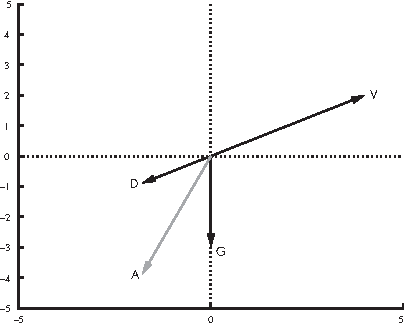

*Figure 12.3: Diagram of velocity, $\mathbf{V}$; acceleration due to drag force, $\mathbf{D}$; acceleration due to gravity, $\mathbf{G}$; and total acceleration, $\mathbf{A}$*

Figure 12.4 shows the results from `ode45`. The ball lands after about 5 s, having traveled less than 150 m, substantially less than what we got without air resistance, about 250 m.

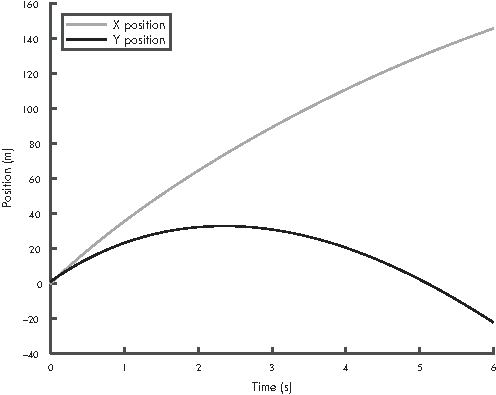

*Figure 12.4: Simulated flight of a baseball including drag force*

This result suggests that ignoring air resistance is not a good choice for modeling a baseball.

## What Could Go Wrong?

What could go wrong? Well, `vertcat` for one. To explain what that means, I’ll start with *concatenation*, which is the operation of joining two matrices into a larger matrix. *Vertical concatenation* joins the matrices by stacking them on top of each other; *horizontal concatenation* lays them side by side.

Here’s an example of horizontal concatenation with row vectors:

In [ ]:
x = 1:3
y = 4:5
z = [x, y]

Inside brackets, the comma operator performs horizontal concatenation. The vertical concatenation operator is the semicolon. Here’s an example with matrices:

In [ ]:
X = zeros(2, 3)
Y = ones(2, 3)
Z = [X; Y]

These operations only work if the matrices are the same size along the dimension where they are glued together. If not, you get

```
>> a = 1:3

a = 1     2     3

>> b = a'

b =  1
     2
     3

>> c = [a, b]
Error using horzcat
Dimensions of matrices being concatenated are not consistent.

>> c = [a; b]
Error using vertcat
Dimensions of matrices being concatenated are not consistent.
```

In Octave, it is:

```
error: horizontal dimensions mismatch (1x3 vs 3x1)
```

In Octave, it is:

```
error: vertical dimensions mismatch (1x3 vs 3x1)
```

In this example, `a` is a row vector and `b` is a column vector, so they can’t be concatenated in either direction.

Reading the error messages, you might guess that `horzcat` is the function that performs horizontal concatenation, and likewise with `vertcat` and vertical concatenation. You would be correct.

In Listing 12.1 we used vertical concatenation to pack `dPdt` and `dVdt` into the output variable:

In [ ]:
function res = rate_func(t, W)
    P = W(1:2);
    V = W(3:4);

    dPdt = V;
    dVdt = acceleration(t, P, V);

    res = [dPdt; dVdt];
end

As long as `dPdt` and `dVdt` are column vectors, the semicolon performs vertical concatenation, and the result is a column vector with four elements. But if either of them is a row vector, that’s trouble.

The `ode45` function expects the result from `rate_func` to be a column vector, so if you are working with `ode45`, it’s probably a good idea to make everything a column vector.

In general, if you run into problems with `horzcat` and `vertcat`, use `size` to display the dimensions of the operands, and make sure you are clear on which way your vectors go.

## Chapter Review

In this chapter, we simulated the flight of a baseball with and without air resistance and saw that the difference is substantial. We can conclude that it’s important to model air resistance if we want to make accurate predictions about baseballs and similar projectiles.

Here are some terms from this chapter you might want to remember.

A *spatial vector* is a value that represents a multidimensional physical quantity like position, velocity, acceleration, or force. A spatial vector has a direction and a magnitude. The magnitude is also called the *norm* of the vector. A *unit vector* is a vector with norm 1, which is often used to represent a direction.

*Concatenation* is the operation of joining two vectors or matrices end-to-end to form a new vector or matrix.

In the next chapter, we’ll continue with the baseball example, using `fzero`, which we saw in Chapter 7, and a new tool for optimization, called `fminsearch`. We’ll also see a simple way to animate the solution of a differential equation.

## Exercises

Before you go on, you might want to work on the following exercises.

**Exercise 12.1.**

When the Boston Red Sox won the World Series in 2007, they played the Colorado Rockies at their home field in Denver, Colorado. Find an estimate of the density of air in the Mile High City. What effect does this have on drag? What effect does it have on the distance the baseball travels?

**Exercise 12.2.**

The actual drag on a baseball is more complicated than what is captured by our simple model. In particular, the drag coefficient depends on velocity. You can get some of the details from Robert K. Adair’s *The Physics of Baseball* (Harper Perennial, 2002); the figure you need is reproduced at <https://greenteapress.com/matlab/drag>.

Use this data to specify a more realistic model of drag and modify your program to implement it. How big is the effect on the distance the baseball travels?

**Exercise 12.3.**

According to Wikipedia, the record distance for a human cannonball is 59.05 m (see <https://greenteapress.com/matlab/cannon>).

Modify the example from this chapter to simulate the flight of a human cannonball. You might have to do some research to find the drag coefficient and cross-sectional area for a flying human.

Find the initial velocity (both magnitude and direction) you would need to break this record. You might have to experiment to find the optimal launch angle.

How much acceleration can a human withstand without injury? At this maximum acceleration, how long would the barrel of the cannon have to be to reach the initial velocity needed to break the record?

In [ ]:
% Exercise 12.1 (air density in Denver): your solution here


In [ ]:
% Exercise 12.2 (drag coefficient that depends on velocity): your solution here


In [ ]:
% Exercise 12.3 (the human cannonball): your solution here
